<a href="https://colab.research.google.com/github/PaloMoshoeshoe/Palo-Moshoeshoe/blob/main/Chapter3_Methodology_DoCC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Interpretable vs black-box models on the Default of Credit Card Clients data
## Implementation of Chapter 3 (Methodology)

This notebook implements the methodology in Chapter 3 end to end: the dataset (§3.4), fold-wise preprocessing (§3.5),
the seven models (§3.6), 10×5 repeated stratified cross-validation (§3.7), surrogate fidelity with error agreement
and a trivial baseline (§3.8), Nadeau–Bengio corrected confidence intervals (§3.9) and the reproducibility
measures of §3.10.

| Stage | What happens | Research question |
|---|---|---|
| 1 | All 7 models are trained on the true target in every fold and scored on the held-out fold | **SQ1**: performance gap |
| 2 | Each of the 4 interpretable models is retrained on each black box's *predicted* labels (12 surrogates) and compared with that black box on the held-out fold | **SQ2**: fidelity, incl. error agreement |

### How to run
1. **Python 3.12 is recommended.** GOSDT 1.0.4 ships pre-built wheels for Python 3.9–3.12 only.
   * **Google Colab:** *Runtime → Change runtime type → Runtime version* → choose a Python 3.12 runtime (e.g. **2026.07**).
     If you stay on Colab's newest runtime (Python 3.13), the setup cell compiles GOSDT from source instead (about 2–3 minutes).
   * **Local Jupyter:** create a Python 3.12 environment, `pip install -r requirements.txt`, and select that kernel.
2. Run the notebook once with `RUN_MODE = "smoke"` (default; roughly 10 minutes) to check that everything installs and runs.
3. Set `RUN_MODE = "full"` for the thesis results. On Colab's free 2-CPU machine the full 10×5 run takes roughly
   **5–6 hours** (about 6–7 minutes per fold, mostly Explainable Boosting Machines; faster with more CPU cores).
   **Results are saved after every fold**, so if the session disconnects you can re-run the notebook and it resumes
   where it stopped (on Colab, keep `SAVE_TO_GOOGLE_DRIVE = True`).
4. Tables (CSV) and figures (PNG and PDF) are written to `docc_interpretability/results_<mode>/` — next to the
   notebook when run locally, or in *My Drive* on Colab.

## 0. Environment setup
The cell below checks the Python version and installs pinned versions of the research packages, so that the results
can be reproduced (§3.10). `numpy`, `pandas`, `scipy` and `matplotlib` are used as provided by the environment
(on Colab 2026.07: numpy 2.0.2, pandas 2.2.2, scipy 1.16.3, matplotlib 3.10.0); their versions are recorded with the results.

In [1]:
import importlib.metadata as _md
import platform
import shutil
import subprocess
import sys

PINNED = {
    "scikit-learn": "1.7.2",   # model training & evaluation; >=1.7 needed for MLP sample weights
    "interpret-core": "0.7.8", # InterpretML's Explainable Boosting Machine (core package, no dashboard extras)
    "gosdt": "1.0.4",          # GOSDT (Lin et al., 2020) incl. threshold guessing (McTavish et al., 2022)
    "ucimlrepo": "0.0.7",      # official UCI ML Repository downloader
    "xlrd": "2.0.2",           # reads the original .xls file
}
UNPINNED = ["numpy", "pandas", "scipy", "matplotlib", "joblib", "tqdm"]

IN_COLAB = "google.colab" in sys.modules
PY = sys.version_info[:2]
print(f"Python {platform.python_version()} on {platform.system()} | running in Colab: {IN_COLAB}")


def _installed(dist):
    try:
        return _md.version(dist)
    except _md.PackageNotFoundError:
        return None


def _pip(*args):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *args])


_missing = [d for d in UNPINNED if _installed(d) is None]
_to_pin = [f"{d}=={v}" for d, v in PINNED.items() if d != "gosdt" and _installed(d) != v]
if _missing or _to_pin:
    print("Installing:", ", ".join(_missing + _to_pin))
    _pip(*_missing, *_to_pin)

if _installed("gosdt") != PINNED["gosdt"]:
    if PY <= (3, 12):
        _pip(f"gosdt=={PINNED['gosdt']}")  # pre-built wheel
    elif IN_COLAB and platform.system() == "Linux":
        print("Python >= 3.13 detected: GOSDT has no pre-built wheel for this version, so it is compiled from "
              "source (about 2-3 minutes). To avoid this, switch the runtime version to a Python 3.12 runtime.")
        subprocess.check_call("apt-get -qq update > /dev/null && apt-get -qq install -y libtbb-dev libgmp-dev "
                              "pkg-config cmake > /dev/null", shell=True)
        _pip("--no-binary=gosdt", f"gosdt=={PINNED['gosdt']}")
    else:
        raise RuntimeError(
            f"GOSDT {PINNED['gosdt']} has pre-built wheels for Python 3.9-3.12 only, but this kernel runs Python "
            f"{platform.python_version()}. Create a Python 3.12 environment, e.g.\n"
            "    conda create -n gosdt312 python=3.12 && conda activate gosdt312\n"
            "    pip install -r requirements.txt && python -m ipykernel install --user --name gosdt312\n"
            "then select the 'gosdt312' kernel and run this notebook again.")

if "sklearn" in sys.modules and sys.modules["sklearn"].__version__ != _installed("scikit-learn"):
    print("WARNING: scikit-learn was upgraded after it had already been imported in this session. "
          "Restart the kernel/session (Colab: Runtime -> Restart session) and run the notebook from the top.")

for _d in list(PINNED) + UNPINNED:
    print(f"  {_d:15s} {_installed(_d)}")

Python 3.12.13 on Linux | running in Colab: True
Installing: scikit-learn==1.7.2, interpret-core==0.7.8, ucimlrepo==0.0.7
  scikit-learn    1.7.2
  interpret-core  0.7.8
  gosdt           1.0.4
  ucimlrepo       0.0.7
  xlrd            2.0.2
  numpy           2.0.2
  pandas          2.2.2
  scipy           1.16.3
  matplotlib      3.10.0
  joblib          1.5.3
  tqdm            4.67.3


In [2]:
import contextlib
import hashlib
import io
import json
import os
import time
import urllib.request
import warnings
import zipfile
from dataclasses import dataclass
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display
from scipy import stats
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight
from tqdm.auto import tqdm

import interpret
from interpret.glassbox import ExplainableBoostingClassifier
import gosdt
from gosdt import GOSDTClassifier, ThresholdGuessBinarizer

# The default MLP (200 epochs) often stops before formal convergence; this is expected for a
# base-level model and is recorded per fold (column `mlp_converged`) instead of printed 50 times.
warnings.filterwarnings("ignore", category=ConvergenceWarning)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

ENVIRONMENT = {
    "python": platform.python_version(), "platform": platform.platform(), "in_colab": IN_COLAB,
    "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__, "interpret": interpret.__version__, "gosdt": gosdt.__version__,
    "joblib": joblib.__version__, "matplotlib": matplotlib.__version__, "cpu_count": os.cpu_count(),
}
print(json.dumps(ENVIRONMENT, indent=2))

{
  "python": "3.12.13",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.35",
  "in_colab": true,
  "numpy": "2.0.2",
  "pandas": "2.2.2",
  "scipy": "1.16.3",
  "scikit-learn": "1.7.2",
  "interpret": "0.7.8",
  "gosdt": "1.0.4",
  "joblib": "1.5.3",
  "matplotlib": "3.10.0",
  "cpu_count": 2
}


## 1. Configuration
Every setting that affects the results is defined here and saved with the results (`run_config.json`).
Settings the chapter does not fix (marked **choice**) are reasonable defaults; whatever values you use should be
reported in the thesis.

* **Random seeds (§3.10):** one fixed seed (`BASE_SEED`) for every model; the five repeats of the 10-fold split use
  seeds `BASE_SEED`…`BASE_SEED + 4`, and every model sees exactly the same splits.
* **Black-box models (§3.6):** base-level, i.e. library defaults, apart from balanced class weights (§3.5).
* **Interpretable models:** library defaults, plus the constraints that make them interpretable: a shared
  maximum tree depth for CART and GOSDT, and GOSDT's sparsity penalty.

In [3]:
RUN_MODE = "smoke"   # "smoke" = quick pipeline check on a 3,000-row subsample; "full" = thesis results

BASE_SEED = 42
ALPHA = 0.05                       # 95% confidence intervals

if RUN_MODE == "full":
    N_SPLITS, N_REPEATS, SUBSAMPLE_N = 10, 5, None
elif RUN_MODE == "smoke":
    N_SPLITS, N_REPEATS, SUBSAMPLE_N = 5, 2, 3_000
else:
    raise ValueError("RUN_MODE must be 'smoke' or 'full'")
CV_SEEDS = [BASE_SEED + r for r in range(N_REPEATS)]

# --- Interpretable models ----------------------------------------------------------------------
MAX_TREE_DEPTH = 4                 # choice: same depth limit for CART and GOSDT (at most 16 leaves)
LR_PARAMS = dict(C=1.0, solver="liblinear", max_iter=1000)   # choice: default strength C=1.0
CART_PARAMS = dict(max_depth=MAX_TREE_DEPTH)
EBM_PARAMS = dict()                # InterpretML defaults (incl. automatic pairwise interactions)
GOSDT_PARAMS = dict(
    regularization=0.001,          # choice: penalty per leaf (on the balanced loss scale)
    depth_budget=MAX_TREE_DEPTH,
    time_limit=300,                # safety limit in seconds per fit; timeouts are recorded
    threshold_n_estimators=40,     # threshold guessing (McTavish et al., 2022), as in the GOSDT examples
    threshold_max_depth=1,
    lower_bound_guessing=False,    # False = exact GOSDT search on the guessed binary features
)

# --- Black-box models: base-level = library defaults ------------------------------------------
RF_PARAMS, GB_PARAMS, MLP_PARAMS = dict(), dict(), dict()

SURROGATE_BALANCED_WEIGHTS = True  # §3.5 "all models": surrogates also use balanced weights on the black-box labels
SURROGATE_TRAINING_LABELS = "in-sample"  # §3.8: black box's predictions on its own training data ("in-sample");
                                         # "out-of-fold" = 5-fold cross-fitted predictions instead (sensitivity check)
assert SURROGATE_TRAINING_LABELS in ("in-sample", "out-of-fold")

if RUN_MODE == "smoke":            # lighter EBM so the pipeline check takes minutes, not hours (full mode: defaults)
    EBM_PARAMS = {**EBM_PARAMS, "outer_bags": 2}

# --- Compute & storage -------------------------------------------------------------------------
N_PARALLEL_FOLDS = 1               # >1 runs several folds at once (useful on machines with many CPU cores)
SAVE_TO_GOOGLE_DRIVE = True        # Colab only: keep checkpoints on Drive so a disconnect loses nothing
PROJECT_NAME = "docc_interpretability"
LOCAL_DATA_FILE = ""               # optional path to a local copy of the dataset (.xls/.xlsx/.csv)

if IN_COLAB and SAVE_TO_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive") / PROJECT_NAME
elif IN_COLAB:
    PROJECT_DIR = Path("/content") / PROJECT_NAME
else:
    PROJECT_DIR = Path.cwd() / PROJECT_NAME

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / f"results_{RUN_MODE}"
FOLD_DIR, TABLE_DIR, FIG_DIR = OUTPUT_DIR / "folds", OUTPUT_DIR / "tables", OUTPUT_DIR / "figures"
for _p in (DATA_DIR, FOLD_DIR, TABLE_DIR, FIG_DIR):
    _p.mkdir(parents=True, exist_ok=True)

INNER_N_JOBS = -1 if N_PARALLEL_FOLDS == 1 else max(1, (os.cpu_count() or 2) // N_PARALLEL_FOLDS)

print(f"RUN_MODE = {RUN_MODE!r}: {N_REPEATS} x {N_SPLITS}-fold CV"
      + (f" on a {SUBSAMPLE_N:,}-row stratified subsample (pipeline check only, not thesis results)" if SUBSAMPLE_N else ""))
print("Results folder:", OUTPUT_DIR)

Mounted at /content/drive
RUN_MODE = 'smoke': 2 x 5-fold CV on a 3,000-row stratified subsample (pipeline check only, not thesis results)
Results folder: /content/drive/MyDrive/docc_interpretability/results_smoke


## 2. Dataset (§3.4)
The Default of Credit Card Clients dataset (Yeh, 2009; UCI id 350, CC BY 4.0) is downloaded from the UCI ML
Repository and cached in `DATA_DIR`, so later runs use the identical file. If the download fails (e.g. no
internet), place the original `default of credit card clients.xls` (or a CSV export) somewhere and set
`LOCAL_DATA_FILE`.

In [4]:
FEATURES = (["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE",
             "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
            + [f"BILL_AMT{i}" for i in range(1, 7)]
            + [f"PAY_AMT{i}" for i in range(1, 7)])
TARGET = "default"
CATEGORICAL = ["SEX", "EDUCATION", "MARRIAGE"]                 # nominal -> one-hot encoding
SCALED = [c for c in FEATURES if c not in CATEGORICAL]         # continuous + ordinal repayment status -> z-score
TARGET_ALIASES = ["default payment next month", "default.payment.next.month", "Y", "default"]
UCI_ID = 350
UCI_ZIP_URL = "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"
CACHE_FILE = DATA_DIR / "default_of_credit_card_clients.csv"


def standardise_docc(raw: pd.DataFrame) -> pd.DataFrame:
    """Return the 23 features (named as in Yeh, 2009) plus a 0/1 target column called 'default'."""
    df = raw.copy()
    df.columns = [str(c).strip() for c in df.columns]
    x_codes = {f"X{i}": name for i, name in enumerate(FEATURES, start=1)}  # UCI codes X1..X23 in documented order
    if set(x_codes).issubset(df.columns) and "LIMIT_BAL" not in df.columns:
        df = df.rename(columns=x_codes)
    target_col = next((c for c in TARGET_ALIASES if c in df.columns), None)
    missing = [c for c in FEATURES if c not in df.columns]
    if target_col is None or missing:
        raise ValueError(f"Unrecognised file layout. Missing features: {missing}; target found: {target_col}")
    df = df[FEATURES + [target_col]].rename(columns={target_col: TARGET})
    return df.apply(pd.to_numeric).astype("int64").reset_index(drop=True)


def read_table(path) -> pd.DataFrame:
    """Read .xls/.xlsx/.csv; handles the original file's two header rows (X1..X23 above the variable names)."""
    path = Path(path)
    reader = pd.read_csv if path.suffix.lower() == ".csv" else pd.read_excel
    df = reader(path)
    if "LIMIT_BAL" not in df.columns and (df.iloc[0].astype(str) == "LIMIT_BAL").any():
        df = reader(path, header=1)
    return df


def load_docc():
    if CACHE_FILE.exists():
        return standardise_docc(pd.read_csv(CACHE_FILE)), f"cached copy ({CACHE_FILE})"
    errors = []
    try:  # 1) the official ucimlrepo package
        from ucimlrepo import fetch_ucirepo
        df, source = standardise_docc(fetch_ucirepo(id=UCI_ID).data.original), f"UCI ML Repository (ucimlrepo, id={UCI_ID})"
    except Exception as e:
        errors.append(f"ucimlrepo: {e}")
        df = None
    if df is None:
        try:  # 2) the original zipped .xls from the UCI website
            zip_path = DATA_DIR / "docc.zip"
            urllib.request.urlretrieve(UCI_ZIP_URL, zip_path)
            with zipfile.ZipFile(zip_path) as z:
                xls_name = next(n for n in z.namelist() if n.lower().endswith((".xls", ".xlsx")))
                z.extract(xls_name, DATA_DIR)
            df, source = standardise_docc(read_table(DATA_DIR / xls_name)), f"UCI ML Repository ({UCI_ZIP_URL})"
        except Exception as e:
            errors.append(f"direct download: {e}")
    if df is None and LOCAL_DATA_FILE:
        df, source = standardise_docc(read_table(LOCAL_DATA_FILE)), f"local file ({LOCAL_DATA_FILE})"
    if df is None:
        raise RuntimeError("Could not obtain the dataset:\n  " + "\n  ".join(errors)
                           + "\nDownload it from https://doi.org/10.24432/C55S3H and set LOCAL_DATA_FILE.")
    df.to_csv(CACHE_FILE, index=False)
    return df, source


data_full, DATA_SOURCE = load_docc()
print("Source:", DATA_SOURCE)
print("SHA-256 of cached file:", hashlib.sha256(CACHE_FILE.read_bytes()).hexdigest()[:16], "...")

if SUBSAMPLE_N:
    data, _ = train_test_split(data_full, train_size=SUBSAMPLE_N, stratify=data_full[TARGET], random_state=BASE_SEED)
    data = data.reset_index(drop=True)
else:
    data = data_full
X_all = data[FEATURES]
y_all = data[TARGET].to_numpy()

Source: UCI ML Repository (ucimlrepo, id=350)
SHA-256 of cached file: e28803eec9921518 ...


### Data checks
The chapter states 30,000 records, 23 explanatory variables, no missing values and about 22% positive cases, and
notes undocumented codes in EDUCATION and MARRIAGE. The cell below verifies these on the downloaded file.
(The repayment-status variables PAY_x also contain the codes −2 and 0, which the UCI documentation does not
describe; following §3.5 they are kept as ordinal values and standardised.)

In [5]:
checks = pd.Series(dtype=object, data={
    "records": len(data_full),
    "explanatory variables": len(FEATURES),
    "missing values": int(data_full.isna().sum().sum()),
    "defaults (positive cases)": int(data_full[TARGET].sum()),
    "default rate": round(data_full[TARGET].mean(), 4),
})
display(checks.to_frame("full dataset"))
if (len(data_full), len(FEATURES)) != (30_000, 23) or checks["missing values"] != 0:
    print("WARNING: the file does not match the description in §3.4 - check the data source.")

documented = {"EDUCATION": {1: "graduate school", 2: "university", 3: "high school", 4: "others"},
              "MARRIAGE": {1: "married", 2: "single", 3: "others"}}
code_rows = []
for var, labels in documented.items():
    for code, n in data_full[var].value_counts().sort_index().items():
        code_rows.append({"variable": var, "code": code, "n": n,
                          "documented meaning": labels.get(code, "UNDOCUMENTED -> merged into 'others'")})
display(pd.DataFrame(code_rows))
print("PAY_x codes observed:", sorted(int(v) for v in pd.unique(data_full[[c for c in FEATURES if c.startswith("PAY_") and "AMT" not in c]].values.ravel())))
if SUBSAMPLE_N:
    print(f"Smoke mode: analysing {len(data):,} rows (default rate {y_all.mean():.3f}).")

,full dataset
records,30000
explanatory variables,23
missing values,0
defaults (positive cases),6636
default rate,0.2212


,variable,code,n,documented meaning
0,EDUCATION,0,14,UNDOCUMENTED -> merged into 'others'
1,EDUCATION,1,10585,graduate school
2,EDUCATION,2,14030,university
3,EDUCATION,3,4917,high school
4,EDUCATION,4,123,others
5,EDUCATION,5,280,UNDOCUMENTED -> merged into 'others'
6,EDUCATION,6,51,UNDOCUMENTED -> merged into 'others'
7,MARRIAGE,0,54,UNDOCUMENTED -> merged into 'others'
8,MARRIAGE,1,13659,married
9,MARRIAGE,2,15964,single


PAY_x codes observed: [-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]
Smoke mode: analysing 3,000 rows (default rate 0.221).


## 3. Preprocessing (§3.5)
All preprocessing lives in one scikit-learn `Pipeline` that is **fitted on the training portion of each fold only**
and then applied unchanged to the held-out portion (Table 3.3):

| Step | Implementation |
|---|---|
| Missing-value check | none required (verified above) |
| Category consolidation | EDUCATION codes 0, 5, 6 → 4 (*others*); MARRIAGE code 0 → 3 (*others*). A fixed recoding that learns nothing from the data |
| Scaling | `StandardScaler` (z-score) on the 14 continuous and 6 repayment-status variables |
| Encoding | `OneHotEncoder` on SEX, EDUCATION, MARRIAGE (all categories kept, unseen categories ignored) |
| Class weighting | balanced weights, applied when each model is fitted (Section 4) |

Because these steps never look at the target, fitting the pipeline once per training fold and sharing it between
the models of that fold gives exactly the same result as refitting it inside every model, and is faster.

In [6]:
EDUCATION_DOCUMENTED, EDUCATION_OTHERS = [1, 2, 3, 4], 4
MARRIAGE_DOCUMENTED, MARRIAGE_OTHERS = [1, 2, 3], 3


def consolidate_categories(X: pd.DataFrame) -> pd.DataFrame:
    """Merge undocumented EDUCATION / MARRIAGE codes into the existing 'others' category."""
    X = X.copy()
    X["EDUCATION"] = X["EDUCATION"].where(X["EDUCATION"].isin(EDUCATION_DOCUMENTED), EDUCATION_OTHERS)
    X["MARRIAGE"] = X["MARRIAGE"].where(X["MARRIAGE"].isin(MARRIAGE_DOCUMENTED), MARRIAGE_OTHERS)
    return X


def make_preprocessor() -> Pipeline:
    encode_and_scale = ColumnTransformer(
        [("zscore", StandardScaler(), SCALED),
         ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=float), CATEGORICAL)],
        verbose_feature_names_out=False)
    return Pipeline([
        ("consolidate", FunctionTransformer(consolidate_categories, feature_names_out="one-to-one")),
        ("encode_and_scale", encode_and_scale),
    ]).set_output(transform="pandas")


# Demonstration on one split: statistics come from the training portion only.
_tr, _te = next(StratifiedKFold(N_SPLITS, shuffle=True, random_state=CV_SEEDS[0]).split(X_all, y_all))
_prep = make_preprocessor().fit(X_all.iloc[_tr])
_Xtr, _Xte = _prep.transform(X_all.iloc[_tr]), _prep.transform(X_all.iloc[_te])
print(f"{_Xtr.shape[1]} model inputs:", list(_Xtr.columns))
display(pd.DataFrame({"training-portion mean": _Xtr[SCALED[:4]].mean(), "held-out mean": _Xte[SCALED[:4]].mean()}).round(4))
print("Scaled training columns have mean 0 by construction; held-out columns do not, because the scaler never saw them.")

29 model inputs: ['LIMIT_BAL', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'SEX_1', 'SEX_2', 'EDUCATION_1', 'EDUCATION_2', 'EDUCATION_3', 'EDUCATION_4', 'MARRIAGE_1', 'MARRIAGE_2', 'MARRIAGE_3']


,training-portion mean,held-out mean
LIMIT_BAL,0.0,-0.0249
AGE,0.0,0.0477
PAY_0,0.0,-0.0121
PAY_2,-0.0,-0.0735


Scaled training columns have mean 0 by construction; held-out columns do not, because the scaler never saw them.


## 4. Models (§3.6)

| Model | Family | Role | Implementation (balanced class weights) |
|---|---|---|---|
| L1-regularised logistic regression | Additive | conventional interpretable | `LogisticRegression` with L1 penalty, `class_weight="balanced"` |
| Explainable Boosting Machine | Additive | flexible interpretable | InterpretML `ExplainableBoostingClassifier`, balanced `sample_weight` |
| Depth-limited CART | Tree-based | conventional interpretable | `DecisionTreeClassifier(max_depth=4)`, `class_weight="balanced"` |
| GOSDT | Tree-based | flexible interpretable | `gosdt.GOSDTClassifier` with `balance=True` (see below) |
| Random forest | Tree ensemble | black box | `RandomForestClassifier()` defaults, `class_weight="balanced"` |
| Gradient boosting | Tree ensemble | black box | `GradientBoostingClassifier()` defaults (Friedman, 2001), balanced `sample_weight` |
| Multilayer perceptron | Neural network | black box | `MLPClassifier()` defaults, balanced `sample_weight` |

`class_weight="balanced"` and balanced `sample_weight` are the same thing: every case of class *c* gets weight
*n* / (2·*n<sub>c</sub>*). GOSDT's `balance=True` uses the same weighting in its misclassification cost.

**GOSDT needs binary inputs.** Following the GOSDT authors' recommended workflow, a *threshold-guessing* step
(McTavish et al., 2022) fits 40 gradient-boosted stumps on the training fold and keeps their split points (minus
any the binarizer's column elimination finds redundant) as binary features of the form `x ≤ t`; GOSDT then finds the
optimal sparse tree over those features, within the depth limit.
Both steps are fitted on the training fold only. GOSDT's own `predict_proba` returns hard 0/1 values, so — exactly as
CART does — the score used for ROC-AUC and PR-AUC is the (balanced) share of defaults among the training cases in
each leaf. Hard predictions, and therefore sensitivity, use GOSDT's own leaf labels.

In [7]:
class GOSDTWithGuessing(ClassifierMixin, BaseEstimator):
    """GOSDT (Lin et al., 2020) with threshold guessing (McTavish et al., 2022) as one scikit-learn estimator."""

    def __init__(self, regularization=0.001, depth_budget=4, time_limit=300, balance=True,
                 threshold_n_estimators=40, threshold_max_depth=1, lower_bound_guessing=False,
                 random_state=0):
        self.regularization = regularization
        self.depth_budget = depth_budget
        self.time_limit = time_limit
        self.balance = balance
        self.threshold_n_estimators = threshold_n_estimators
        self.threshold_max_depth = threshold_max_depth
        self.lower_bound_guessing = lower_bound_guessing
        self.random_state = random_state

    def fit(self, X, y):
        y = np.asarray(y).astype(int)
        self.classes_ = np.array([0, 1])
        self.feature_names_in_ = np.asarray(X.columns) if hasattr(X, "columns") else None
        # 1) threshold guessing: binary features x_j <= t learned from the training data only
        self.binarizer_ = ThresholdGuessBinarizer(n_estimators=self.threshold_n_estimators,
                                                  max_depth=self.threshold_max_depth,
                                                  random_state=self.random_state)
        Xb = self.binarizer_.fit(X, y).transform(X).astype(bool)
        self.n_binary_features_ = Xb.shape[1]
        weights = compute_sample_weight("balanced", y) if self.balance else np.ones(len(y))
        # 2) optional lower-bound guessing with a reference boosting model
        y_ref = None
        if self.lower_bound_guessing:
            ref = GradientBoostingClassifier(n_estimators=self.threshold_n_estimators,
                                             max_depth=self.threshold_max_depth, random_state=self.random_state)
            y_ref = ref.fit(Xb, y, sample_weight=weights).predict(Xb)
            if set(np.unique(y_ref)) != set(np.unique(y)):
                y_ref = None  # GOSDT requires the reference labels to contain the same classes
        # 3) optimal sparse tree search (GOSDT prints its warnings; they are captured and kept in `messages_`)
        self.gosdt_ = GOSDTClassifier(regularization=self.regularization, depth_budget=self.depth_budget,
                                      time_limit=self.time_limit, balance=self.balance)
        buffer, start = io.StringIO(), time.perf_counter()
        with contextlib.redirect_stdout(buffer):
            self.gosdt_.fit(Xb, y, y_ref=y_ref, input_features=list(self.binarizer_.get_feature_names_out()))
        self.search_seconds_ = time.perf_counter() - start
        self.messages_ = buffer.getvalue().strip()
        self.status_ = str(self.gosdt_.result_.status).split(".")[-1]   # CONVERGED / TIMEOUT / ...
        # Compile the tree into plain tuples: ("leaf", label) or ("split", binary_feature, true_child, false_child)
        self.nodes_ = []
        self._compile(self.gosdt_.trees_[0].tree)
        self.leaf_nodes_ = [i for i, node in enumerate(self.nodes_) if node[0] == "leaf"]
        self.n_leaves_ = len(self.leaf_nodes_)
        self.depth_ = self._depth(0)
        # Leaf scores: (weighted) share of positive training cases per leaf, as in CART's predict_proba
        leaf = self._leaf_index(Xb)
        pos = np.bincount(leaf, weights=weights * (y == 1), minlength=self.n_leaves_)
        tot = np.bincount(leaf, weights=weights, minlength=self.n_leaves_)
        self.leaf_label_ = np.array([self.nodes_[i][1] for i in self.leaf_nodes_], dtype=int)
        self.leaf_score_ = np.where(tot > 0, pos / np.maximum(tot, 1e-12), self.leaf_label_.astype(float))
        self.leaf_n_train_ = np.bincount(leaf, minlength=self.n_leaves_)
        return self

    def _compile(self, node):
        index = len(self.nodes_)
        self.nodes_.append(None)
        if hasattr(node, "prediction"):
            label = int(self.gosdt_.classes_[node.prediction]) if len(self.gosdt_.classes_) > 1 \
                else int(self.gosdt_.classes_[0])
            self.nodes_[index] = ("leaf", label)
        else:
            true_child = self._compile(node.left_child)     # in GOSDT the left child is the TRUE branch
            false_child = self._compile(node.right_child)
            self.nodes_[index] = ("split", int(node.feature), true_child, false_child)
        return index

    def _depth(self, i):
        node = self.nodes_[i]
        return 0 if node[0] == "leaf" else 1 + max(self._depth(node[2]), self._depth(node[3]))

    def _leaf_index(self, Xb):
        position = {node_id: k for k, node_id in enumerate(self.leaf_nodes_)}
        out = np.empty(Xb.shape[0], dtype=int)
        stack = [(0, np.arange(Xb.shape[0]))]
        while stack:
            i, rows = stack.pop()
            node = self.nodes_[i]
            if node[0] == "leaf":
                out[rows] = position[i]
            else:
                is_true = Xb[rows, node[1]]
                stack += [(node[2], rows[is_true]), (node[3], rows[~is_true])]
        return out

    def _binarize(self, X):
        return self.binarizer_.transform(X).astype(bool)

    def predict(self, X):
        return self.leaf_label_[self._leaf_index(self._binarize(X))]

    def predict_proba(self, X):
        p = self.leaf_score_[self._leaf_index(self._binarize(X))]
        return np.column_stack([1 - p, p])

In [8]:
@dataclass(frozen=True)
class ModelSpec:
    name: str
    short: str
    family: str
    role: str            # "interpretable" or "black-box"
    balance_via: str     # how balanced class weights are applied: "class_weight", "sample_weight" or "balance"
    make: callable       # n_jobs -> unfitted estimator


def _l1_logistic(**params):
    """L1 logistic regression; scikit-learn >= 1.8 replaces penalty='l1' by l1_ratio=1."""
    import inspect
    if inspect.signature(LogisticRegression).parameters["penalty"].default == "deprecated":
        return LogisticRegression(l1_ratio=1.0, **params)
    return LogisticRegression(penalty="l1", **params)


MODELS = [
    ModelSpec("L1 logistic regression", "L1-LR", "Additive", "interpretable", "class_weight",
              lambda n_jobs: _l1_logistic(random_state=BASE_SEED, **LR_PARAMS)),
    ModelSpec("Explainable Boosting Machine", "EBM", "Additive", "interpretable", "sample_weight",
              lambda n_jobs: ExplainableBoostingClassifier(random_state=BASE_SEED, n_jobs=n_jobs, **EBM_PARAMS)),
    ModelSpec("Depth-limited CART", "CART", "Tree-based", "interpretable", "class_weight",
              lambda n_jobs: DecisionTreeClassifier(random_state=BASE_SEED, **CART_PARAMS)),
    ModelSpec("GOSDT", "GOSDT", "Tree-based", "interpretable", "balance",
              lambda n_jobs: GOSDTWithGuessing(random_state=BASE_SEED, **GOSDT_PARAMS)),
    ModelSpec("Random forest", "RF", "Tree ensemble", "black-box", "class_weight",
              lambda n_jobs: RandomForestClassifier(random_state=BASE_SEED, n_jobs=n_jobs, **RF_PARAMS)),
    ModelSpec("Gradient boosting", "GB", "Tree ensemble", "black-box", "sample_weight",
              lambda n_jobs: GradientBoostingClassifier(random_state=BASE_SEED, **GB_PARAMS)),
    ModelSpec("Multilayer perceptron", "MLP", "Neural network", "black-box", "sample_weight",
              lambda n_jobs: MLPClassifier(random_state=BASE_SEED, **MLP_PARAMS)),
]
SPEC = {m.name: m for m in MODELS}
INTERPRETABLE = [m.name for m in MODELS if m.role == "interpretable"]
BLACK_BOX = [m.name for m in MODELS if m.role == "black-box"]
BASELINE = "Trivial baseline"


def build_and_fit(name, X, y, balanced=True, n_jobs=1):
    """Create a fresh model and fit it, applying balanced class weights in the way the model supports."""
    spec = SPEC[name]
    model = spec.make(n_jobs)
    if balanced and spec.balance_via == "class_weight":
        model.set_params(class_weight="balanced")
    elif spec.balance_via == "balance":
        model.set_params(balance=balanced)
    fit_kwargs = {"sample_weight": compute_sample_weight("balanced", y)} \
        if balanced and spec.balance_via == "sample_weight" else {}
    start = time.perf_counter()
    model.fit(X, y, **fit_kwargs)
    return model, time.perf_counter() - start


def positive_score(model, X):
    return model.predict_proba(X)[:, list(model.classes_).index(1)]


def model_diagnostics(model) -> dict:
    """Small descriptive record of model size / convergence (not an outcome of the study)."""
    if isinstance(model, LogisticRegression):
        return {"model_size": int(np.count_nonzero(model.coef_)), "size_unit": "non-zero coefficients"}
    if isinstance(model, DecisionTreeClassifier):
        return {"model_size": int(model.get_n_leaves()), "size_unit": "leaves", "tree_depth": int(model.get_depth())}
    if isinstance(model, GOSDTWithGuessing):
        return {"model_size": model.n_leaves_, "size_unit": "leaves", "tree_depth": model.depth_,
                "gosdt_status": model.status_, "gosdt_binary_features": model.n_binary_features_,
                "gosdt_search_seconds": round(model.search_seconds_, 3)}
    if isinstance(model, ExplainableBoostingClassifier):
        return {"model_size": len(model.term_features_), "size_unit": "terms (main + pairwise)"}
    if isinstance(model, MLPClassifier):
        return {"mlp_converged": bool(model.n_iter_ < model.max_iter)}
    return {}


display(pd.DataFrame([{"model": m.name, "short": m.short, "family": m.family, "role": m.role,
                       "balanced weights via": m.balance_via} for m in MODELS]))

,model,short,family,role,balanced weights via
0,L1 logistic regression,L1-LR,Additive,interpretable,class_weight
1,Explainable Boosting Machine,EBM,Additive,interpretable,sample_weight
2,Depth-limited CART,CART,Tree-based,interpretable,class_weight
3,GOSDT,GOSDT,Tree-based,interpretable,balance
4,Random forest,RF,Tree ensemble,black-box,class_weight
5,Gradient boosting,GB,Tree ensemble,black-box,sample_weight
6,Multilayer perceptron,MLP,Neural network,black-box,sample_weight


## 5. Evaluation protocol (§3.7) and fidelity measurement (§3.8)

**Cross-validation.** 10-fold stratified cross-validation, repeated 5 times with seeds `BASE_SEED`…`BASE_SEED + 4`
→ 50 train/test splits, identical for every model.

**Performance metrics (Table 3.6)**, computed on each held-out fold:
* **ROC-AUC** (primary) from the predicted probability of default.
* **PR-AUC** as *average precision* (the step-wise estimator of the area under the precision–recall curve; the
  trapezoidal rule is optimistic for PR curves).
* **Sensitivity** = recall of the default class at each model's own decision rule (`predict`).
* Accuracy and specificity are stored for reference only (not primary outcomes).

**Fidelity (Table 3.7).** In every fold, each black box *B* is trained on the true labels; its predictions on the
training portion, *ŷ<sub>B</sub>*, become the training labels for each interpretable surrogate *S* (12 surrogates).
By default these are *B*'s predictions on its own training data (the usual global-surrogate set-up). Note that a
random forest reproduces almost all of its training labels, so its surrogates are trained on labels close to the
truth; setting `SURROGATE_TRAINING_LABELS = "out-of-fold"` uses 5-fold cross-fitted black-box predictions instead,
as a sensitivity check (it multiplies the black-box training time by about five). On the held-out portion:
* **overall agreement** = share of cases where *S* and *B* predict the same label;
* **error agreement** = among the cases *B* misclassifies, the share where *S* returns the same (incorrect) label;
* **correct-case agreement** = the same share among the cases *B* gets right (supplementary; overall agreement is
  a weighted average of the two);
* **trivial baseline** = a "surrogate" that always predicts *B*'s most common label on the training portion.
  Its error agreement is simply the share of *B*'s errors that carry that majority label.

In [9]:
def performance_metrics(y_true, score, pred) -> dict:
    y_true, pred = np.asarray(y_true), np.asarray(pred)
    return {
        "roc_auc": roc_auc_score(y_true, score),
        "pr_auc": average_precision_score(y_true, score),
        "sensitivity": recall_score(y_true, pred, pos_label=1),
        "specificity": recall_score(y_true, pred, pos_label=0),
        "accuracy": accuracy_score(y_true, pred),
    }


def fidelity_metrics(bb_pred, surrogate_pred, bb_wrong) -> dict:
    agree = np.asarray(surrogate_pred) == np.asarray(bb_pred)
    return {
        "overall_agreement": agree.mean(),
        "error_agreement": agree[bb_wrong].mean() if bb_wrong.any() else np.nan,
        "correct_agreement": agree[~bb_wrong].mean() if (~bb_wrong).any() else np.nan,
        "n_bb_errors": int(bb_wrong.sum()),
    }


@dataclass(frozen=True)
class Fold:
    repeat: int
    fold: int
    seed: int
    train_idx: np.ndarray
    test_idx: np.ndarray

    @property
    def key(self):
        return f"r{self.repeat}_f{self.fold:02d}"


def make_folds(y, n_splits, seeds):
    folds = []
    for r, seed in enumerate(seeds, start=1):
        skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        for k, (tr, te) in enumerate(skf.split(np.zeros(len(y)), y), start=1):
            folds.append(Fold(r, k, seed, tr, te))
    return folds


def run_fold(f: Fold, X, y, n_jobs=-1) -> dict:
    warnings.filterwarnings("ignore", category=ConvergenceWarning)  # repeated here for parallel worker processes
    ids = {"repeat": f.repeat, "fold": f.fold, "cv_seed": f.seed}
    y_tr, y_te = y[f.train_idx], y[f.test_idx]

    # §3.5: preprocessing fitted on the training portion only
    prep = make_preprocessor().fit(X.iloc[f.train_idx])
    X_tr, X_te = prep.transform(X.iloc[f.train_idx]), prep.transform(X.iloc[f.test_idx])

    performance, fidelity, black_boxes = [], [], {}
    # Stage 1 (SQ1): all seven models on the true target
    for name in INTERPRETABLE + BLACK_BOX:
        model, seconds = build_and_fit(name, X_tr, y_tr, balanced=True, n_jobs=n_jobs)
        performance.append({**ids, "model": name, "role": SPEC[name].role, "family": SPEC[name].family,
                            **performance_metrics(y_te, positive_score(model, X_te), model.predict(X_te)),
                            "fit_seconds": round(seconds, 3), "n_train": len(y_tr), "n_test": len(y_te),
                            **model_diagnostics(model)})
        if name in BLACK_BOX:
            black_boxes[name] = model

    # Stage 2 (SQ2): surrogates trained on each black box's predicted labels
    for bb_name, bb in black_boxes.items():
        yhat_te = bb.predict(X_te)
        if SURROGATE_TRAINING_LABELS == "in-sample":
            yhat_tr = bb.predict(X_tr)
        else:  # cross-fitted: each training case is labelled by a copy of the black box that did not see it
            yhat_tr = np.empty_like(y_tr)
            inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=BASE_SEED)
            for a, b in inner.split(X_tr, y_tr):
                bb_copy, _ = build_and_fit(bb_name, X_tr.iloc[a], y_tr[a], balanced=True, n_jobs=n_jobs)
                yhat_tr[b] = bb_copy.predict(X_tr.iloc[b])
        if np.unique(yhat_tr).size < 2:
            raise RuntimeError(f"{bb_name} predicts a single class in {f.key}; surrogates cannot be trained.")
        bb_wrong = yhat_te != y_te
        common = {**ids, "black_box": bb_name, "n_train": len(y_tr), "n_test": len(y_te),
                  "bb_positive_rate_train": yhat_tr.mean()}
        majority = int(np.bincount(yhat_tr).argmax())
        fidelity.append({**common, "surrogate": BASELINE, "majority_label": majority,
                         **fidelity_metrics(yhat_te, np.full_like(yhat_te, majority), bb_wrong)})
        for s_name in INTERPRETABLE:
            surrogate, seconds = build_and_fit(s_name, X_tr, yhat_tr, balanced=SURROGATE_BALANCED_WEIGHTS,
                                               n_jobs=n_jobs)
            fidelity.append({**common, "surrogate": s_name,
                             **fidelity_metrics(yhat_te, surrogate.predict(X_te), bb_wrong),
                             "fit_seconds": round(seconds, 3), **model_diagnostics(surrogate)})
    return {"key": f.key, "performance": performance, "fidelity": fidelity}

## 6. Run the experiment
Each fold's results are written to `results_<mode>/folds/<key>.json` as soon as the fold finishes. Re-running this
cell skips folds that are already saved, so an interrupted run resumes where it stopped. A fingerprint of the
configuration is stored with the results; if you change a setting, the notebook refuses to mix old and new results
(delete the results folder or change `PROJECT_NAME` first).

In [10]:
RUN_CONFIG = {
    "run_mode": RUN_MODE, "n_rows": int(len(data)), "subsample_n": SUBSAMPLE_N, "n_splits": N_SPLITS,
    "n_repeats": N_REPEATS, "cv_seeds": CV_SEEDS, "base_seed": BASE_SEED,
    "surrogate_balanced_weights": SURROGATE_BALANCED_WEIGHTS, "surrogate_training_labels": SURROGATE_TRAINING_LABELS,
    "data_sha256": hashlib.sha256(pd.util.hash_pandas_object(data, index=False).values.tobytes()).hexdigest(),
    "models": {m.name: {"class": type(m.make(1)).__name__, "balanced_via": m.balance_via,
                        "params": {k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v))
                                   for k, v in m.make(1).get_params().items()}}
               for m in MODELS},
}
CONFIG_HASH = hashlib.sha256(json.dumps(RUN_CONFIG, sort_keys=True, default=str).encode()).hexdigest()[:12]
config_file = OUTPUT_DIR / "run_config.json"
if config_file.exists():
    previous = json.loads(config_file.read_text(encoding="utf-8"))
    if previous.get("config_hash") != CONFIG_HASH:
        raise RuntimeError(f"{OUTPUT_DIR} holds results from a different configuration (hash "
                           f"{previous.get('config_hash')} vs {CONFIG_HASH}). Delete that folder or change PROJECT_NAME.")
    if previous.get("environment", {}).get("scikit-learn") != ENVIRONMENT["scikit-learn"]:
        print("WARNING: resuming with a different scikit-learn version than the one that started this run.")
else:
    config_file.write_text(json.dumps({**RUN_CONFIG, "config_hash": CONFIG_HASH, "data_source": DATA_SOURCE,
                                       "environment": ENVIRONMENT}, indent=2, default=str), encoding="utf-8")

FOLDS = make_folds(y_all, N_SPLITS, CV_SEEDS)
for f in FOLDS:  # stratification and leakage checks
    assert np.intersect1d(f.train_idx, f.test_idx).size == 0
    assert abs(y_all[f.test_idx].mean() - y_all.mean()) < 0.01
TEST_TRAIN_RATIO = float(np.mean([len(f.test_idx) / len(f.train_idx) for f in FOLDS]))


def _fold_file(f):
    return FOLD_DIR / f"{f.key}.json"


def run_and_save(f):
    result = run_fold(f, X_all, y_all, n_jobs=INNER_N_JOBS)
    result["config_hash"] = CONFIG_HASH
    tmp = _fold_file(f).with_suffix(".tmp")
    tmp.write_text(json.dumps(result, default=lambda o: o.item() if hasattr(o, "item") else str(o)), encoding="utf-8")
    os.replace(tmp, _fold_file(f))   # atomic: a fold file is either complete or absent
    return f.key


pending = [f for f in FOLDS if not _fold_file(f).exists()]
print(f"{len(FOLDS)} folds in total, {len(FOLDS) - len(pending)} already saved, {len(pending)} to run "
      f"(test/train size ratio = {TEST_TRAIN_RATIO:.4f}).")
start = time.perf_counter()
if pending and N_PARALLEL_FOLDS == 1:
    for f in tqdm(pending, desc="folds"):
        run_and_save(f)
elif pending:
    joblib.Parallel(n_jobs=N_PARALLEL_FOLDS, verbose=10)(joblib.delayed(run_and_save)(f) for f in pending)
print(f"Finished in {(time.perf_counter() - start) / 60:.1f} min.")

10 folds in total, 0 already saved, 10 to run (test/train size ratio = 0.2500).


folds:   0%|          | 0/10 [00:00<?, ?it/s]

Finished in 19.4 min.


In [11]:
def load_results():
    missing = [f.key for f in FOLDS if not _fold_file(f).exists()]
    if missing:
        raise RuntimeError(f"{len(missing)} of {len(FOLDS)} folds have no saved results yet (e.g. {missing[0]}). "
                           "Run the experiment cell above to completion first - it resumes where it stopped.")
    perf, fid = [], []
    for f in FOLDS:
        record = json.loads(_fold_file(f).read_text(encoding="utf-8"))
        if record.get("config_hash") != CONFIG_HASH:
            raise RuntimeError(f"{_fold_file(f).name} was produced with a different configuration.")
        perf += record["performance"]
        fid += record["fidelity"]
    return pd.DataFrame(perf), pd.DataFrame(fid)


perf_df, fid_df = load_results()
assert len(perf_df) == len(FOLDS) * len(MODELS)
assert len(fid_df) == len(FOLDS) * len(BLACK_BOX) * (len(INTERPRETABLE) + 1)
perf_df.to_csv(TABLE_DIR / "per_fold_performance.csv", index=False)
fid_df.to_csv(TABLE_DIR / "per_fold_fidelity.csv", index=False)
print(f"Loaded {len(perf_df)} performance rows and {len(fid_df)} fidelity rows from {len(FOLDS)} folds.")
display(perf_df[["repeat", "fold", "model", "roc_auc", "pr_auc", "sensitivity", "fit_seconds"]].head(7))

Loaded 70 performance rows and 150 fidelity rows from 10 folds.


,repeat,fold,model,roc_auc,pr_auc,sensitivity,fit_seconds
0,1,1,L1 logistic regression,0.736289,0.514926,0.651515,0.072
1,1,1,Explainable Boosting Machine,0.766058,0.571217,0.613636,31.890
2,1,1,Depth-limited CART,0.712510,0.494313,0.636364,0.036
3,1,1,GOSDT,0.708722,0.390885,0.560606,1.088
4,1,1,Random forest,0.751643,0.488936,0.242424,0.770
5,1,1,Gradient boosting,0.755763,0.549455,0.590909,1.748
6,1,1,Multilayer perceptron,0.722708,0.476809,0.530303,7.727


## 7. Statistical analysis (§3.9)
The 50 fold results share training data, so they are not independent and the naive standard error of their mean
is too small. All confidence intervals therefore use the **corrected resampled t** of Nadeau and Bengio (2003),
in the form used for repeated *k*-fold cross-validation (Bouckaert & Frank, 2004), implemented by hand below:

$$\hat\sigma^2_{\text{corr}} = \Big(\frac{1}{J} + \frac{n_{\text{test}}}{n_{\text{train}}}\Big)\,s^2,\qquad
  \text{CI}_{95\%} = \bar d \pm t_{J-1,\,0.975}\,\hat\sigma_{\text{corr}},\qquad t = \bar d / \hat\sigma_{\text{corr}}$$

where *d* are the *J* = 50 per-fold values (or paired per-fold differences) and *s*² their sample variance. The
same estimator is used for per-model means, the SQ1 differences (interpretable − black box, paired by fold), the
SQ2 agreement measures and their differences from the trivial baseline. Holm-adjusted *p*-values across the 12
comparisons are added as a supplementary safeguard against multiple testing.

In [12]:
def corrected_resampled_t(values, test_train_ratio=TEST_TRAIN_RATIO, alpha=ALPHA) -> dict:
    """Mean, corrected 95% CI, t and two-sided p (H0: mean = 0) - Nadeau & Bengio (2003)."""
    x = np.asarray(values, dtype=float)
    x = x[~np.isnan(x)]
    J = x.size
    mean, var = x.mean(), x.var(ddof=1)
    se = np.sqrt((1.0 / J + test_train_ratio) * var)
    t_crit = stats.t.ppf(1 - alpha / 2, df=J - 1)
    t_stat = mean / se if se > 0 else np.nan
    p = 2 * stats.t.sf(abs(t_stat), df=J - 1) if np.isfinite(t_stat) else np.nan
    return {"mean": mean, "ci_low": mean - t_crit * se, "ci_high": mean + t_crit * se,
            "se_corrected": se, "t": t_stat, "df": J - 1, "p": p, "J": J}


def holm_adjust(pvalues):
    p = np.asarray(pvalues, dtype=float)
    order = np.argsort(p)
    adjusted = np.empty_like(p)
    running_max = 0.0
    for rank, i in enumerate(order):
        running_max = max(running_max, (len(p) - rank) * p[i])
        adjusted[i] = min(1.0, running_max)
    return adjusted


def ci_text(mean, low, high, digits=3):
    return f"{mean:.{digits}f} [{low:.{digits}f}, {high:.{digits}f}]"


J = len(FOLDS)
print(f"J = {J} resamples, n_test/n_train = {TEST_TRAIN_RATIO:.4f}")
print(f"variance factor: corrected {1 / J + TEST_TRAIN_RATIO:.4f} vs naive {1 / J:.4f} "
      f"-> corrected intervals are {np.sqrt((1 / J + TEST_TRAIN_RATIO) * J):.2f}x wider than naive ones")

MODEL_ORDER = INTERPRETABLE + BLACK_BOX
METRICS = {"roc_auc": "ROC-AUC", "pr_auc": "PR-AUC", "sensitivity": "Sensitivity",
           "specificity": "Specificity (ref.)", "accuracy": "Accuracy (ref.)"}

J = 10 resamples, n_test/n_train = 0.2500
variance factor: corrected 0.3500 vs naive 0.1000 -> corrected intervals are 1.87x wider than naive ones


### 7.1 Performance of each model (50 held-out folds)

In [13]:
rows = []
for name in MODEL_ORDER:
    sub = perf_df[perf_df["model"] == name]
    for metric, label in METRICS.items():
        r = corrected_resampled_t(sub[metric])
        rows.append({"model": name, "role": SPEC[name].role, "metric": label, "mean": r["mean"],
                     "ci_low": r["ci_low"], "ci_high": r["ci_high"], "sd_across_folds": sub[metric].std(ddof=1)})
performance_summary = pd.DataFrame(rows)
performance_summary.to_csv(TABLE_DIR / "table_performance.csv", index=False)

table_performance = (performance_summary
                     .assign(value=lambda d: [ci_text(*v) for v in d[["mean", "ci_low", "ci_high"]].to_numpy()])
                     .pivot(index="model", columns="metric", values="value")
                     .loc[MODEL_ORDER, list(METRICS.values())])
table_performance.insert(0, "role", [SPEC[m].role for m in MODEL_ORDER])
table_performance.to_csv(TABLE_DIR / "table_performance_formatted.csv")
print("Mean [95% corrected CI] across the held-out folds")
display(table_performance)

Mean [95% corrected CI] across the held-out folds


metric,role,ROC-AUC,PR-AUC,Sensitivity,Specificity (ref.),Accuracy (ref.)
model,,,,,,
L1 logistic regression,interpretable,"0.724 [0.683, 0.765]","0.508 [0.451, 0.565]","0.651 [0.582, 0.719]","0.682 [0.650, 0.714]","0.675 [0.651, 0.699]"
Explainable Boosting Machine,interpretable,"0.769 [0.741, 0.797]","0.545 [0.508, 0.581]","0.605 [0.551, 0.659]","0.820 [0.796, 0.843]","0.772 [0.756, 0.788]"
Depth-limited CART,interpretable,"0.727 [0.679, 0.775]","0.482 [0.431, 0.533]","0.576 [0.494, 0.659]","0.780 [0.696, 0.864]","0.735 [0.678, 0.792]"
GOSDT,interpretable,"0.713 [0.675, 0.752]","0.411 [0.335, 0.488]","0.553 [0.512, 0.593]","0.841 [0.820, 0.863]","0.778 [0.764, 0.791]"
Random forest,black-box,"0.754 [0.733, 0.776]","0.498 [0.458, 0.538]","0.306 [0.258, 0.353]","0.948 [0.934, 0.962]","0.806 [0.795, 0.816]"
Gradient boosting,black-box,"0.763 [0.739, 0.788]","0.532 [0.492, 0.572]","0.592 [0.548, 0.636]","0.816 [0.787, 0.845]","0.766 [0.747, 0.785]"
Multilayer perceptron,black-box,"0.723 [0.702, 0.745]","0.464 [0.433, 0.496]","0.550 [0.500, 0.600]","0.771 [0.741, 0.801]","0.722 [0.699, 0.745]"


### 7.2 SQ1 — difference in discrimination (interpretable − black box)
Positive values favour the interpretable model. The primary comparison is ROC-AUC; PR-AUC and sensitivity follow
as secondary metrics.

In [14]:
def paired_differences(metric):
    wide = perf_df.pivot_table(index=["repeat", "fold"], columns="model", values=metric)
    out = []
    for bb in BLACK_BOX:
        for im in INTERPRETABLE:
            d = (wide[im] - wide[bb]).to_numpy()
            r = corrected_resampled_t(d)
            out.append({"metric": METRICS[metric], "interpretable": im, "black_box": bb,
                        "mean_difference": r["mean"], "ci_low": r["ci_low"], "ci_high": r["ci_high"],
                        "t": r["t"], "df": r["df"], "p": r["p"],
                        "folds_interpretable_better": int((d > 0).sum())})
    out = pd.DataFrame(out)
    out["p_holm"] = holm_adjust(out["p"])
    out["conclusion (95% CI)"] = np.select([out["ci_high"] < 0, out["ci_low"] > 0],
                                           ["black box better", "interpretable better"], "no clear difference")
    return out


sq1 = pd.concat([paired_differences(m) for m in ["roc_auc", "pr_auc", "sensitivity"]], ignore_index=True)
sq1.to_csv(TABLE_DIR / "table_sq1_differences.csv", index=False)


def show_sq1(metric_label, digits=3):
    t = sq1[sq1["metric"] == metric_label].copy()
    t["difference [95% CI]"] = [ci_text(*v, digits=digits) for v in t[["mean_difference", "ci_low", "ci_high"]].to_numpy()]
    t["t"], t["p"], t["p_holm"] = t["t"].round(2), t["p"].map("{:.4f}".format), t["p_holm"].map("{:.4f}".format)
    return t[["black_box", "interpretable", "difference [95% CI]", "t", "df", "p", "p_holm",
              "folds_interpretable_better", "conclusion (95% CI)"]].reset_index(drop=True)


for label in ["ROC-AUC", "PR-AUC", "Sensitivity"]:
    print(f"\nSQ1 - {label} difference (interpretable - black box), {J} paired folds")
    display(show_sq1(label))


SQ1 - ROC-AUC difference (interpretable - black box), 10 paired folds


,black_box,interpretable,difference [95% CI],t,df,p,p_holm,folds_interpretable_better,conclusion (95% CI)
0,Random forest,L1 logistic regression,"-0.030 [-0.071, 0.012]",-1.63,9,0.1375,0.9626,2,no clear difference
1,Random forest,Explainable Boosting Machine,"0.015 [-0.008, 0.037]",1.47,9,0.1769,1.0000,7,no clear difference
2,Random forest,Depth-limited CART,"-0.027 [-0.070, 0.016]",-1.42,9,0.1887,1.0000,3,no clear difference
3,Random forest,GOSDT,"-0.041 [-0.091, 0.009]",-1.87,9,0.0949,0.7593,3,no clear difference
4,Gradient boosting,L1 logistic regression,"-0.039 [-0.080, 0.003]",-2.11,9,0.0642,0.6259,2,no clear difference
5,Gradient boosting,Explainable Boosting Machine,"0.006 [-0.017, 0.028]",0.57,9,0.5836,1.0000,5,no clear difference
6,Gradient boosting,Depth-limited CART,"-0.036 [-0.074, 0.002]",-2.12,9,0.0626,0.6259,1,no clear difference
7,Gradient boosting,GOSDT,"-0.050 [-0.096, -0.003]",-2.43,9,0.0378,0.4161,1,black box better
8,Multilayer perceptron,L1 logistic regression,"0.001 [-0.035, 0.037]",0.05,9,0.9597,1.0000,7,no clear difference
9,Multilayer perceptron,Explainable Boosting Machine,"0.045 [0.027, 0.064]",5.56,9,0.0004,0.0042,10,interpretable better



SQ1 - PR-AUC difference (interpretable - black box), 10 paired folds


,black_box,interpretable,difference [95% CI],t,df,p,p_holm,folds_interpretable_better,conclusion (95% CI)
0,Random forest,L1 logistic regression,"0.011 [-0.060, 0.081]",0.34,9,0.7439,1.0000,5,no clear difference
1,Random forest,Explainable Boosting Machine,"0.047 [-0.003, 0.097]",2.13,9,0.0618,0.4947,9,no clear difference
2,Random forest,Depth-limited CART,"-0.015 [-0.067, 0.036]",-0.68,9,0.5163,1.0000,4,no clear difference
3,Random forest,GOSDT,"-0.086 [-0.174, 0.002]",-2.21,9,0.0543,0.4888,1,no clear difference
4,Gradient boosting,L1 logistic regression,"-0.024 [-0.088, 0.040]",-0.84,9,0.4206,1.0000,3,no clear difference
5,Gradient boosting,Explainable Boosting Machine,"0.013 [-0.022, 0.047]",0.83,9,0.4298,1.0000,6,no clear difference
6,Gradient boosting,Depth-limited CART,"-0.050 [-0.083, -0.017]",-3.39,9,0.0080,0.0878,0,black box better
7,Gradient boosting,GOSDT,"-0.121 [-0.202, -0.040]",-3.38,9,0.0082,0.0878,0,black box better
8,Multilayer perceptron,L1 logistic regression,"0.044 [-0.011, 0.098]",1.82,9,0.1025,0.7176,8,no clear difference
9,Multilayer perceptron,Explainable Boosting Machine,"0.080 [0.053, 0.107]",6.77,9,0.0001,0.0010,10,interpretable better



SQ1 - Sensitivity difference (interpretable - black box), 10 paired folds


,black_box,interpretable,difference [95% CI],t,df,p,p_holm,folds_interpretable_better,conclusion (95% CI)
0,Random forest,L1 logistic regression,"0.345 [0.260, 0.429]",9.22,9,0.0000,0.0001,10,interpretable better
1,Random forest,Explainable Boosting Machine,"0.300 [0.235, 0.364]",10.51,9,0.0000,0.0000,10,interpretable better
2,Random forest,Depth-limited CART,"0.270 [0.175, 0.365]",6.44,9,0.0001,0.0011,10,interpretable better
3,Random forest,GOSDT,"0.247 [0.198, 0.296]",11.44,9,0.0000,0.0000,10,interpretable better
4,Gradient boosting,L1 logistic regression,"0.059 [-0.003, 0.120]",2.16,9,0.0586,0.3516,9,no clear difference
5,Gradient boosting,Explainable Boosting Machine,"0.014 [-0.018, 0.045]",0.97,9,0.3552,1.0000,5,no clear difference
6,Gradient boosting,Depth-limited CART,"-0.016 [-0.070, 0.038]",-0.66,9,0.5243,1.0000,2,no clear difference
7,Gradient boosting,GOSDT,"-0.039 [-0.088, 0.009]",-1.82,9,0.1016,0.5079,2,no clear difference
8,Multilayer perceptron,L1 logistic regression,"0.101 [0.048, 0.154]",4.33,9,0.0019,0.0152,10,interpretable better
9,Multilayer perceptron,Explainable Boosting Machine,"0.056 [0.022, 0.089]",3.74,9,0.0046,0.0322,10,interpretable better


### 7.3 SQ2 — fidelity of the 12 surrogates
Agreement with the black box on held-out data. For each black box the first row is the trivial baseline; the
"vs baseline" columns give the surrogate's advantage over it (paired by fold).

In [15]:
MEASURES = {"overall_agreement": "Overall agreement", "error_agreement": "Error agreement",
            "correct_agreement": "Correct-case agreement"}
rows = []
for bb in BLACK_BOX:
    base = fid_df[(fid_df["black_box"] == bb) & (fid_df["surrogate"] == BASELINE)].set_index(["repeat", "fold"])
    for s in [BASELINE] + INTERPRETABLE:
        sub = fid_df[(fid_df["black_box"] == bb) & (fid_df["surrogate"] == s)].set_index(["repeat", "fold"]).loc[base.index]
        row = {"black_box": bb, "surrogate": s}
        for col in MEASURES:
            r = corrected_resampled_t(sub[col])
            row |= {col: r["mean"], f"{col}_ci_low": r["ci_low"], f"{col}_ci_high": r["ci_high"]}
            if s != BASELINE:
                d = corrected_resampled_t(sub[col] - base[col])
                row |= {f"{col}_vs_baseline": d["mean"], f"{col}_vs_baseline_ci_low": d["ci_low"],
                        f"{col}_vs_baseline_ci_high": d["ci_high"], f"{col}_vs_baseline_p": d["p"]}
        rows.append(row)
sq2 = pd.DataFrame(rows)
sq2.to_csv(TABLE_DIR / "table_sq2_fidelity.csv", index=False)

pretty = sq2[["black_box", "surrogate"]].copy()
for col, label in MEASURES.items():
    pretty[label] = [ci_text(*v) for v in sq2[[col, f"{col}_ci_low", f"{col}_ci_high"]].to_numpy()]
for col, label in list(MEASURES.items())[:2]:
    vals = sq2[[f"{col}_vs_baseline", f"{col}_vs_baseline_ci_low", f"{col}_vs_baseline_ci_high"]].to_numpy()
    pretty[f"{label} vs baseline"] = ["—" if np.isnan(v[0]) else ci_text(*v) for v in vals]
pretty.to_csv(TABLE_DIR / "table_sq2_fidelity_formatted.csv", index=False)
print("Mean [95% corrected CI] across the held-out folds")
display(pretty)

bb_context = (fid_df[fid_df["surrogate"] == BASELINE]
              .assign(bb_error_rate=lambda d: d["n_bb_errors"] / d["n_test"])
              .groupby("black_box")
              .agg(error_rate=("bb_error_rate", "mean"), errors_per_fold=("n_bb_errors", "mean"),
                   predicted_positive_rate_train=("bb_positive_rate_train", "mean"),
                   majority_label=("majority_label", lambda s: ", ".join(str(int(v)) for v in sorted(set(s)))))
              .loc[BLACK_BOX])
print("Context: how often each black box is wrong on held-out data (the cases behind 'error agreement')")
display(bb_context.round(4))

Mean [95% corrected CI] across the held-out folds


,black_box,surrogate,Overall agreement,Error agreement,Correct-case agreement,Overall agreement vs baseline,Error agreement vs baseline
0,Random forest,Trivial baseline,"0.892 [0.874, 0.910]","0.792 [0.742, 0.841]","0.916 [0.904, 0.929]",—,—
1,Random forest,L1 logistic regression,"0.713 [0.677, 0.749]","0.598 [0.500, 0.695]","0.741 [0.711, 0.771]","-0.179 [-0.224, -0.134]","-0.194 [-0.323, -0.065]"
2,Random forest,Explainable Boosting Machine,"0.832 [0.807, 0.857]","0.654 [0.582, 0.726]","0.875 [0.853, 0.896]","-0.060 [-0.095, -0.024]","-0.138 [-0.241, -0.034]"
3,Random forest,Depth-limited CART,"0.804 [0.727, 0.882]","0.679 [0.585, 0.773]","0.834 [0.754, 0.915]","-0.087 [-0.173, -0.002]","-0.113 [-0.232, 0.007]"
4,Random forest,GOSDT,"0.858 [0.843, 0.872]","0.707 [0.657, 0.758]","0.894 [0.882, 0.906]","-0.034 [-0.056, -0.012]","-0.084 [-0.159, -0.010]"
5,Gradient boosting,Trivial baseline,"0.726 [0.696, 0.755]","0.388 [0.334, 0.442]","0.829 [0.815, 0.843]",—,—
6,Gradient boosting,L1 logistic regression,"0.815 [0.786, 0.843]","0.766 [0.696, 0.837]","0.829 [0.803, 0.856]","0.089 [0.046, 0.132]","0.378 [0.299, 0.458]"
7,Gradient boosting,Explainable Boosting Machine,"0.878 [0.660, 1.096]","0.863 [0.783, 0.942]","0.882 [0.615, 1.149]","0.152 [-0.049, 0.353]","0.475 [0.415, 0.534]"
8,Gradient boosting,Depth-limited CART,"0.874 [0.826, 0.922]","0.815 [0.758, 0.872]","0.891 [0.833, 0.950]","0.148 [0.093, 0.203]","0.427 [0.339, 0.515]"
9,Gradient boosting,GOSDT,"0.885 [0.856, 0.913]","0.821 [0.770, 0.873]","0.904 [0.864, 0.944]","0.159 [0.117, 0.200]","0.433 [0.361, 0.506]"


Context: how often each black box is wrong on held-out data (the cases behind 'error agreement')


,error_rate,errors_per_fold,predicted_positive_rate_train,majority_label
black_box,,,,
Random forest,0.1942,116.5,0.2213,0
Gradient boosting,0.2337,140.2,0.2871,0
Multilayer perceptron,0.2780,166.8,0.3071,0


### 7.4 Diagnostics
Model size and run-time descriptors, plus checks that GOSDT searches finished (status `CONVERGED`) rather than
stopping at the time limit. These are descriptive only.

In [16]:
diag = (pd.concat([perf_df.assign(stage="original target", surrogate_of="—"),
                   fid_df[fid_df["surrogate"] != BASELINE].rename(columns={"surrogate": "model", "black_box": "surrogate_of"})
                   .assign(stage="surrogate")], ignore_index=True))
size_table = (diag[diag["model"].isin(INTERPRETABLE)]
              .groupby(["model", "stage", "surrogate_of"], sort=False)
              .agg(size_mean=("model_size", "mean"), size_min=("model_size", "min"), size_max=("model_size", "max"),
                   size_unit=("size_unit", "first"), fit_seconds_mean=("fit_seconds", "mean")))
display(size_table.round(2))

gosdt_rows = diag[diag["model"] == "GOSDT"]
print("GOSDT search status counts:", gosdt_rows["gosdt_status"].value_counts().to_dict())
if (gosdt_rows["gosdt_status"] != "CONVERGED").any():
    print("WARNING: some GOSDT searches hit the time limit; those trees are not proven optimal. "
          "Increase GOSDT_PARAMS['time_limit'] or 'regularization' and re-run.")
print("GOSDT binary features per fit: median", gosdt_rows["gosdt_binary_features"].median(),
      "| range", int(gosdt_rows["gosdt_binary_features"].min()), "-", int(gosdt_rows["gosdt_binary_features"].max()))
print(f"MLP reached formal convergence within max_iter in "
      f"{perf_df.loc[perf_df['model'] == 'Multilayer perceptron', 'mlp_converged'].astype(bool).mean():.0%} of folds.")
display(perf_df.groupby("model", sort=False)["fit_seconds"].mean().loc[MODEL_ORDER].round(2).to_frame("mean fit seconds (stage 1)"))

,,,size_mean,size_min,size_max,size_unit,fit_seconds_mean
model,stage,surrogate_of,,,,,
L1 logistic regression,original target,—,25.2,24.0,27.0,non-zero coefficients,0.07
Explainable Boosting Machine,original target,—,116.0,116.0,116.0,terms (main + pairwise),26.73
Depth-limited CART,original target,—,15.4,15.0,16.0,leaves,0.03
GOSDT,original target,—,4.4,2.0,11.0,leaves,0.94
L1 logistic regression,surrogate,Random forest,25.2,24.0,27.0,non-zero coefficients,0.08
Explainable Boosting Machine,surrogate,Random forest,116.0,116.0,116.0,terms (main + pairwise),26.17
Depth-limited CART,surrogate,Random forest,15.4,15.0,16.0,leaves,0.03
GOSDT,surrogate,Random forest,4.4,2.0,11.0,leaves,1.10
L1 logistic regression,surrogate,Gradient boosting,25.7,24.0,27.0,non-zero coefficients,0.10


GOSDT search status counts: {'CONVERGED': 40}
GOSDT binary features per fit: median 10.0 | range 2 - 18
MLP reached formal convergence within max_iter in 0% of folds.


,mean fit seconds (stage 1)
model,
L1 logistic regression,0.07
Explainable Boosting Machine,26.73
Depth-limited CART,0.03
GOSDT,0.94
Random forest,0.86
Gradient boosting,2.06
Multilayer perceptron,5.78


## 8. Figures
Saved to `results_<mode>/figures/` as PNG (300 dpi) and PDF. Each point is a mean; horizontal bars are the
corrected 95% confidence intervals.

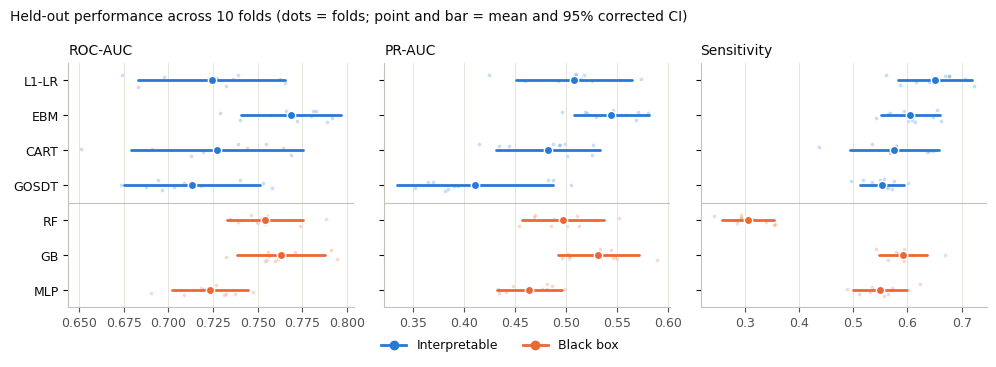

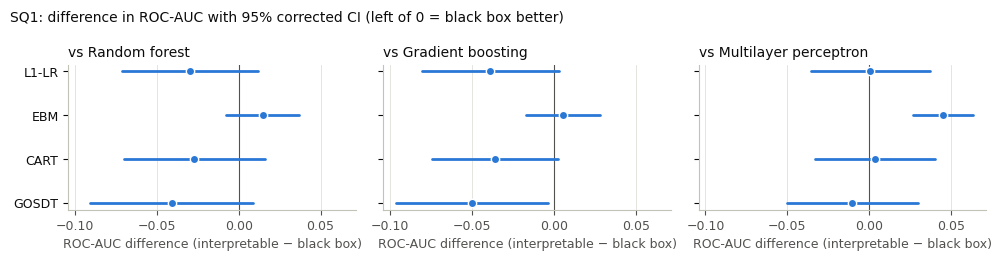

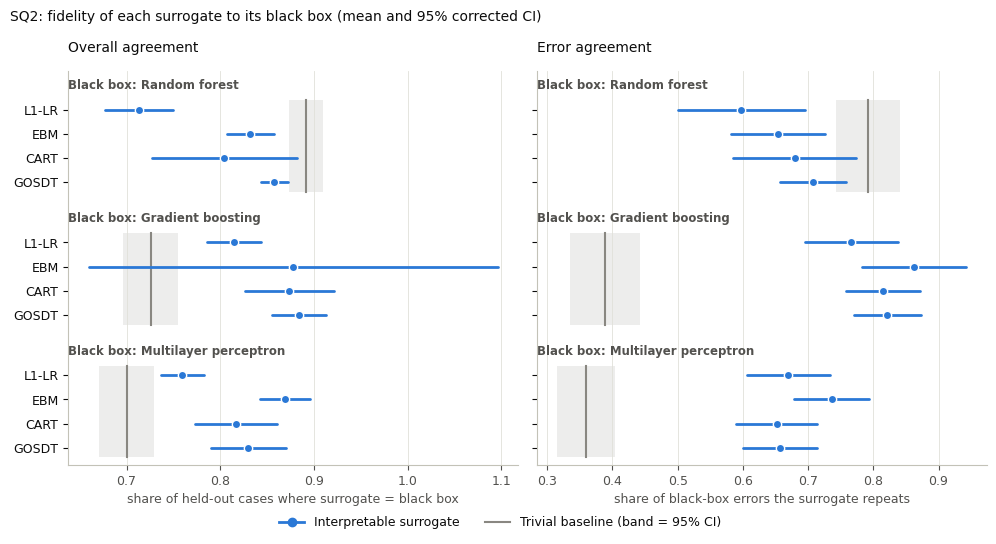

In [17]:
COLOR = {"interpretable": "#2a78d6", "black-box": "#eb6834", "baseline": "#898781"}
INK, INK_2, GRID, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
SHORT = {m.name: m.short for m in MODELS}
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9, "text.color": INK, "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "x",
    "grid.color": GRID, "grid.linewidth": 0.6, "legend.frameon": False,
})


def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", dpi=300, bbox_inches="tight")


# Figure 1 - performance of each model across folds
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True)
ypos = {m: i for i, m in enumerate(reversed(MODEL_ORDER))}
rng = np.random.default_rng(0)
for ax, metric in zip(axes, ["roc_auc", "pr_auc", "sensitivity"]):
    for m in MODEL_ORDER:
        vals = perf_df.loc[perf_df["model"] == m, metric].to_numpy()
        c = COLOR[SPEC[m].role]
        ax.scatter(vals, ypos[m] + rng.uniform(-0.18, 0.18, vals.size), s=7, color=c, alpha=0.25, linewidths=0)
        r = corrected_resampled_t(vals)
        ax.plot([r["ci_low"], r["ci_high"]], [ypos[m]] * 2, color=c, lw=2, solid_capstyle="round")
        ax.plot(r["mean"], ypos[m], "o", ms=6, color=c, markeredgecolor="white", markeredgewidth=1)
    ax.set_title(METRICS[metric], loc="left")
    ax.axhline(len(BLACK_BOX) - 0.5, color=AXIS, lw=0.8)
axes[0].set_yticks(list(ypos.values()), [SHORT[m] for m in ypos])
handles = [plt.Line2D([], [], marker="o", ls="-", lw=2, ms=6, color=COLOR[r], label=l)
           for r, l in [("interpretable", "Interpretable"), ("black-box", "Black box")]]
fig.legend(handles=handles, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.06))
fig.suptitle(f"Held-out performance across {J} folds (dots = folds; point and bar = mean and 95% corrected CI)",
             x=0.01, ha="left", fontsize=10)
fig.tight_layout()
save(fig, "fig1_performance")
plt.show()

# Figure 2 - SQ1: ROC-AUC difference, one panel per black box
roc = sq1[sq1["metric"] == "ROC-AUC"]
fig, axes = plt.subplots(1, len(BLACK_BOX), figsize=(10, 2.6), sharex=True, sharey=True)
ylab = {m: i for i, m in enumerate(reversed(INTERPRETABLE))}
for ax, bb in zip(axes, BLACK_BOX):
    sub = roc[roc["black_box"] == bb]
    ax.axvline(0, color=INK_2, lw=0.8)
    for _, r in sub.iterrows():
        ax.plot([r["ci_low"], r["ci_high"]], [ylab[r["interpretable"]]] * 2, color=COLOR["interpretable"], lw=2,
                solid_capstyle="round")
        ax.plot(r["mean_difference"], ylab[r["interpretable"]], "o", ms=6, color=COLOR["interpretable"],
                markeredgecolor="white", markeredgewidth=1)
    ax.set_title(f"vs {bb}", loc="left")
    ax.set_xlabel("ROC-AUC difference (interpretable − black box)")
axes[0].set_yticks(list(ylab.values()), [SHORT[m] for m in ylab])
fig.suptitle("SQ1: difference in ROC-AUC with 95% corrected CI (left of 0 = black box better)",
             x=0.01, ha="left", fontsize=10)
fig.tight_layout()
save(fig, "fig2_sq1_roc_auc_differences")
plt.show()

# Figure 3 - SQ2: overall and error agreement, surrogates vs trivial baseline
XLABEL3 = {"overall_agreement": "share of held-out cases where surrogate = black box",
           "error_agreement": "share of black-box errors the surrogate repeats"}
ypos3, header_y, y = {}, {}, 0.0
for bb in BLACK_BOX:              # one block of rows per black box, with a header row on top
    header_y[bb], y = y, y - 1
    for s in INTERPRETABLE:
        ypos3[(bb, s)], y = y, y - 1
    y -= 0.5
fig, axes = plt.subplots(1, 2, figsize=(10, 5.2), sharey=True)
for ax, col in zip(axes, ["overall_agreement", "error_agreement"]):
    for bb in BLACK_BOX:
        b = sq2[(sq2["black_box"] == bb) & (sq2["surrogate"] == BASELINE)].iloc[0]
        ys = [ypos3[(bb, s)] for s in INTERPRETABLE]
        ax.fill_betweenx([min(ys) - 0.4, max(ys) + 0.4], b[f"{col}_ci_low"], b[f"{col}_ci_high"],
                         color=COLOR["baseline"], alpha=0.15, linewidth=0)
        ax.plot([b[col]] * 2, [min(ys) - 0.4, max(ys) + 0.4], color=COLOR["baseline"], lw=1.5)
        ax.text(0.0, header_y[bb], f"Black box: {bb}", transform=ax.get_yaxis_transform(), ha="left",
                va="center", fontsize=8.5, fontweight="bold", color=INK_2)
        for s in INTERPRETABLE:
            r = sq2[(sq2["black_box"] == bb) & (sq2["surrogate"] == s)].iloc[0]
            ax.plot([r[f"{col}_ci_low"], r[f"{col}_ci_high"]], [ypos3[(bb, s)]] * 2, color=COLOR["interpretable"],
                    lw=2, solid_capstyle="round")
            ax.plot(r[col], ypos3[(bb, s)], "o", ms=6, color=COLOR["interpretable"], markeredgecolor="white",
                    markeredgewidth=1)
    ax.set_title(MEASURES[col], loc="left", pad=14)
    ax.set_xlabel(XLABEL3[col])
    ax.set_ylim(min(ypos3.values()) - 0.7, 0.6)
axes[0].set_yticks(list(ypos3.values()), [SHORT[s] for _, s in ypos3])
handles = [plt.Line2D([], [], marker="o", lw=2, ms=6, color=COLOR["interpretable"], label="Interpretable surrogate"),
           plt.Line2D([], [], lw=1.5, color=COLOR["baseline"], label="Trivial baseline (band = 95% CI)")]
fig.legend(handles=handles, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("SQ2: fidelity of each surrogate to its black box (mean and 95% corrected CI)", x=0.01, ha="left",
             fontsize=10)
fig.tight_layout()
save(fig, "fig3_sq2_fidelity")
plt.show()

## 9. Save the record of this run (§3.10)

In [18]:
(OUTPUT_DIR / "environment.json").write_text(json.dumps(ENVIRONMENT, indent=2), encoding="utf-8")
print("Configuration hash:", CONFIG_HASH)
print("Output folder:", OUTPUT_DIR)
for p in sorted(OUTPUT_DIR.rglob("*")):
    if p.is_file() and p.parent.name != "folds":
        print("  ", p.relative_to(OUTPUT_DIR))
print(f"   folds/ ({len(list(FOLD_DIR.glob('*.json')))} per-fold checkpoint files)")
if RUN_MODE != "full":
    print("\nReminder: these are SMOKE-TEST results on a subsample. Set RUN_MODE = 'full' for the thesis.")

Configuration hash: 9ce781a5c403
Output folder: /content/drive/MyDrive/docc_interpretability/results_smoke
   environment.json
   figures/fig1_performance.pdf
   figures/fig1_performance.png
   figures/fig2_sq1_roc_auc_differences.pdf
   figures/fig2_sq1_roc_auc_differences.png
   figures/fig3_sq2_fidelity.pdf
   figures/fig3_sq2_fidelity.png
   run_config.json
   tables/per_fold_fidelity.csv
   tables/per_fold_performance.csv
   tables/table_performance.csv
   tables/table_performance_formatted.csv
   tables/table_sq1_differences.csv
   tables/table_sq2_fidelity.csv
   tables/table_sq2_fidelity_formatted.csv
   folds/ (10 per-fold checkpoint files)

Reminder: these are SMOKE-TEST results on a subsample. Set RUN_MODE = 'full' for the thesis.


## Appendix A. What the interpretable models look like (illustration only)
Not part of the evaluation. Each interpretable model is fitted once on all analysed records, with the same
preprocessing and settings, so it can be shown and discussed. Tree thresholds are translated back from z-scores
to the original units (NT dollars, months of delay, years).

In [19]:
RUN_APPENDIX = True

if RUN_APPENDIX:
    prep_all = make_preprocessor().fit(X_all)
    Xp = prep_all.transform(X_all)
    zscore = prep_all.named_steps["encode_and_scale"].named_transformers_["zscore"]
    MEAN, SD = dict(zip(SCALED, zscore.mean_)), dict(zip(SCALED, zscore.scale_))

    def condition(column, threshold):
        if column in MEAN:  # scaled variable: back-transform the threshold
            return f"{column} <= {threshold * SD[column] + MEAN[column]:,.1f}"
        variable, category = column.rsplit("_", 1)   # one-hot indicator: value <= 0.5 means 'not this category'
        return f"{variable} != {category}"

    def rules(children, cond, leaf, node=0, depth=0):
        kids = children(node)
        if kids is None:
            return ["    " * depth + leaf(node)]
        return (["    " * depth + f"if {cond(node)}:"] + rules(children, cond, leaf, kids[0], depth + 1)
                + ["    " * depth + "else:"] + rules(children, cond, leaf, kids[1], depth + 1))

    def leaf_text(label, mask):
        return f"-> {'DEFAULT' if label == 1 else 'no default'}   (n = {mask.sum():,}, observed default rate {y_all[mask].mean():.1%})"

    # L1 logistic regression: coefficients per standard deviation (z-scored inputs)
    lr, _ = build_and_fit("L1 logistic regression", Xp, y_all)
    coef = pd.Series(lr.coef_[0], index=Xp.columns)
    print(f"L1 logistic regression: {np.count_nonzero(coef)} of {coef.size} coefficients are non-zero "
          f"(intercept {lr.intercept_[0]:.3f}). Largest effects (log-odds per SD / per category):")
    display(coef[coef != 0].sort_values(key=np.abs, ascending=False).head(12).round(3).to_frame("coefficient"))

    # Depth-limited CART
    cart, _ = build_and_fit("Depth-limited CART", Xp, y_all)
    t, cart_leaf = cart.tree_, cart.apply(Xp)
    print(f"\nDepth-limited CART ({cart.get_n_leaves()} leaves, depth {cart.get_depth()}):")
    print("\n".join(rules(
        lambda i: None if t.children_left[i] == -1 else (t.children_left[i], t.children_right[i]),
        lambda i: condition(Xp.columns[t.feature[i]], t.threshold[i]),
        lambda i: leaf_text(int(cart.classes_[np.argmax(t.value[i][0])]), cart_leaf == i))))

    # GOSDT
    g, _ = build_and_fit("GOSDT", Xp, y_all)
    g_leaf = g._leaf_index(g._binarize(Xp))
    print(f"\nGOSDT ({g.n_leaves_} leaves, depth {g.depth_}, status {g.status_}, "
          f"{g.n_binary_features_} guessed binary features):")
    print("\n".join(rules(
        lambda i: None if g.nodes_[i][0] == "leaf" else (g.nodes_[i][2], g.nodes_[i][3]),
        lambda i: condition(Xp.columns[g.binarizer_.thresholds_[g.nodes_[i][1]][0]],
                            g.binarizer_.thresholds_[g.nodes_[i][1]][1]),
        lambda i: leaf_text(g.nodes_[i][1], g_leaf == g.leaf_nodes_.index(i)))))

    # EBM: most important terms (mean absolute contribution to the log-odds)
    ebm, _ = build_and_fit("Explainable Boosting Machine", Xp, y_all, n_jobs=-1)
    importance = pd.Series(ebm.term_importances(), index=ebm.term_names_).sort_values(ascending=False)
    print(f"\nExplainable Boosting Machine: {len(importance)} terms; top 12 by mean |contribution|:")
    display(importance.head(12).round(4).to_frame("importance"))

L1 logistic regression: 25 of 29 coefficients are non-zero (intercept -0.103). Largest effects (log-odds per SD / per category):


,coefficient
PAY_0,0.655
BILL_AMT1,-0.574
PAY_AMT2,-0.566
EDUCATION_4,-0.480
MARRIAGE_3,0.401
PAY_AMT4,-0.264
MARRIAGE_2,-0.235
BILL_AMT2,0.216
PAY_AMT1,-0.182
BILL_AMT5,0.168



Depth-limited CART (15 leaves, depth 4):
if PAY_0 <= 0.5:
    if PAY_AMT5 <= 1,122.0:
        if PAY_2 <= 1.0:
            if LIMIT_BAL <= 25,000.0:
                -> DEFAULT   (n = 121, observed default rate 29.8%)
            else:
                -> no default   (n = 799, observed default rate 16.8%)
        else:
            if PAY_AMT2 <= 616.0:
                -> DEFAULT   (n = 11, observed default rate 100.0%)
            else:
                -> no default   (n = 8, observed default rate 12.5%)
    else:
        if PAY_3 <= 1.0:
            if PAY_AMT6 <= 2,464.0:
                -> no default   (n = 510, observed default rate 11.4%)
            else:
                -> no default   (n = 774, observed default rate 6.3%)
        else:
            if PAY_AMT2 <= 2,350.0:
                -> DEFAULT   (n = 59, observed default rate 33.9%)
            else:
                -> no default   (n = 10, observed default rate 0.0%)
else:
    if PAY_0 <= 1.5:
        if PAY_AMT1 <= 3,849.

,importance
PAY_0,0.5726
PAY_AMT5,0.1228
PAY_AMT2,0.1058
PAY_3,0.0898
PAY_AMT1,0.0871
LIMIT_BAL,0.0792
PAY_2,0.0760
PAY_AMT3,0.0740
PAY_AMT6,0.0738
PAY_4,0.0654


## Notes for the write-up
Implementation details that the chapter does not (yet) state and that are worth reporting, with the values used
here (all set in Section 1):
* **Software versions** — printed at the top and saved in `environment.json` (e.g. Python 3.12, scikit-learn 1.7.2,
  interpret 0.7.8, gosdt 1.0.4).
* **Tree depth** — CART and GOSDT share `MAX_TREE_DEPTH = 4`. **GOSDT** uses per-leaf regularisation 0.001 on the
  balanced loss, threshold guessing with 40 boosted stumps (McTavish et al., 2022), no lower-bound guessing, and a
  300-second safety time limit (all searches should report `CONVERGED`).
* **GOSDT scores for ROC-AUC/PR-AUC** — leaf-level share of defaults among training cases, as for CART.
* **CART** — scikit-learn defaults apart from `max_depth` (no minimum leaf size, so a few leaves can be very small).
* **L1 logistic regression** — `C = 1.0`, liblinear solver.
* **PR-AUC** — estimated as average precision.
* **Sensitivity** — at each model's own decision rule (`predict`), which for class-weighted models corresponds to a
  balanced operating point.
* **Surrogates** — trained on each black box's predictions for its own training portion, with balanced weights
  computed from those predicted labels (§3.5 "all models"). Because a random forest reproduces almost all of its
  training labels, consider reporting the `"out-of-fold"` variant as a sensitivity check.
* **Trivial baseline** — always predicts the black box's most common *training-portion* label.
* **Confidence intervals** — corrected resampled t (Nadeau & Bengio, 2003; Bouckaert & Frank, 2004) for every
  reported mean and difference, with *J* = 50 and *n*<sub>test</sub>/*n*<sub>train</sub> = 1/9; Holm-adjusted
  *p*-values are supplementary.